In [1]:
import skysurvey as ss

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/ligo/skymap/bayestar/__init__.py:34: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
snia = ss.SNeIa()

In [5]:
snia.template_parameters

['z', 't0', 'x0', 'x1', 'c']

In [13]:
help(snia.get_rate)

Help on method get_rate in module skysurvey.target.core:

get_rate(z, rate=None, **kwargs) method of skysurvey.target.snia.SNeIa instance
    Get the number of target (per year) up to the given redshift.

    Parameters
    ----------
    z : float
        Redshift.
    rate : float, callable, optional
        If None, `self.rate` is used.
        If a float is given, it is assumed to be the number of targets per
        Gpc3. If a callable is given, it is supposed to be a function of z that
        returns the volumetric rate as a function of wavelength.
    **kwargs
        Goes to the rate function (if a function, not a number).

    Returns
    -------
    int
        The number of targets.

    See Also
    --------
    draw_redshift: draws redshifts from rate distribution.



In [15]:
snia.get_rate(0.1)

23500.0

In [16]:
from pprint import pprint
pprint(snia.model.model)


{'c': {'func': <function SNeIaColor.intrinsic_and_dust at 0x11f2662a0>,
       'kwargs': {}},
 'magabs': {'func': <function SNeIaMagnitude.tripp1998 at 0x11f2663e0>,
            'kwargs': {'c': '@c', 'mabs': -19.3, 'sigmaint': 0.1, 'x1': '@x1'}},
 'magobs': {'func': 'magabs_to_magobs',
            'kwargs': {'magabs': '@magabs', 'z': '@z'}},
 'radec': {'as': ['ra', 'dec'],
           'func': <function random_radec at 0x11f213240>,
           'kwargs': {}},
 'redshift': {'as': 'z',
              'func': 'draw_redshift',
              'kwargs': {'rate': 23500.0, 'zmax': 0.2}},
 't0': {'func': <bound method Generator.uniform of Generator(PCG64) at 0x123FF6F80>,
        'kwargs': {'high': 56200, 'low': 56000}},
 'x1': {'func': <function SNeIaStretch.nicolas2021 at 0x11f266340>,
        'kwargs': {}}}


In [30]:
data = snia.draw(size=10)
snia

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/sncosmo/models.py:189: RuntimeWarning: divide by zero encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)


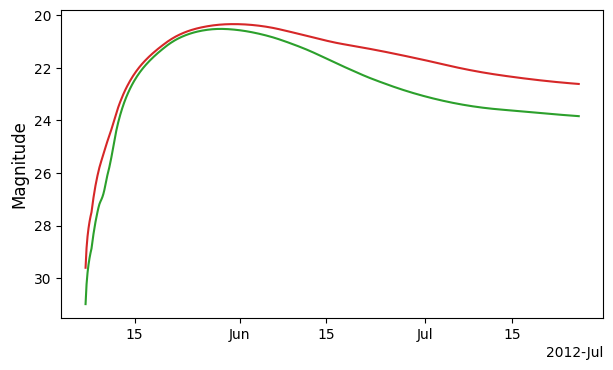

In [29]:
snia = ss.SNeIa.from_draw(10000)
band = ["ztfr","ztfg"]
fig = snia.show_lightcurve(band, index=10, in_mag=True)

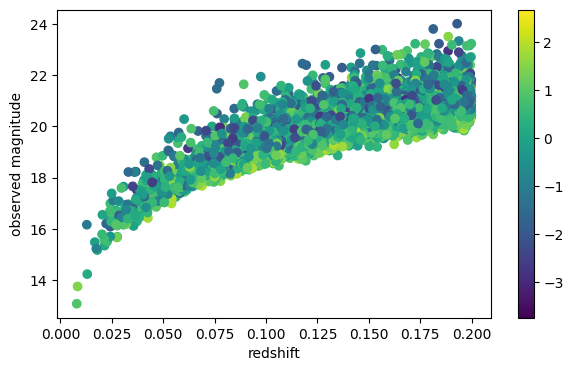

In [28]:
fig = snia.show_scatter("z", "magobs", ckey="x1") 
ax = fig.axes[0]

_ = ax.set_ylabel("observed magnitude")
_ = ax.set_xlabel("redshift")

In [31]:
opsim_path = "baseline_v5.1.0_10yrs.db" # provide fullpath
lsst = ss.LSST.from_opsim(opsim_path)
lsst.data

DatabaseError: Execution failed on sql 'SELECT fieldRA, fieldDec, observationStartMJD, visitExposureTime, filter, skyBrightness, fiveSigmaDepth, night, numExposures, observationId FROM OBSERVATIONS ': no such table: OBSERVATIONS